# LSTM y BiLSTM para Sleep-EDFx en MPS

Campaña sobre los mismos **62 sujetos de desarrollo**, 122 registros y 152.052 segmentos supervisados de la referencia. Cinco folds congelados por sujeto; los 16 sujetos de test permanecen reservados.

Métrica primaria: **F1 macro promedio entre folds**. Secundarias: accuracy, kappa y F1 por estadio. El mejor modelo neuronal y el ganador global se declaran por separado. La comparación entre variantes es exploratoria.

Este notebook revisa artefactos guardados por defecto. `RUN_TRAINING=True` inicia explícitamente el runner con MPS obligatorio; todas las corridas se registran en MLflow.

In [1]:
from pathlib import Path
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "0")
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
import torch
from sleep_staging.config import CLASSES
from sleep_staging.evaluation import evaluate
from sleep_staging.provenance import hash_file
from sleep_staging.lstm_research import run_lstm_campaign

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
OUTPUT = ROOT / "var/research/sc-w30-lstm-mps-v1"
REFERENCE = ROOT / "var/research/sc-w30-v2/campaign.json"
CONFIG = ROOT / "configs/research/lstm-mps.yaml"
RUN_TRAINING = False
PRIMARY_METRIC = "f1_macro"
SECONDARY_METRICS = ["accuracy", "kappa"]
CLASSES_5 = CLASSES["task_5"]
print({"python": platform.python_version(), "torch": torch.__version__, "mps_available": torch.backends.mps.is_available(), "fallback": os.environ.get("PYTORCH_ENABLE_MPS_FALLBACK")})


/Users/adrianalarcon/.paradev/projects/maia_proyecto/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.12.0', 'torch': '2.14.1', 'mps_available': True, 'fallback': '0'}


## Hipótesis y ventanas

Se usan 145 características de EEG Fpz-Cz, EEG Pz-Oz, EOG y envolvente EMG nativa. No son 145 muestras de señal cruda.

- `lstm_single_epoch`: control con un segmento de 30 segundos.
- `lstm_past15`: 14 segmentos anteriores y el objetivo actual.
- `bilstm_center15`: siete segmentos anteriores, objetivo central y siete posteriores.

Las ventanas conservan señales de segmentos M disponibles sin introducir sus etiquetas y se reinician en cada registro y hueco temporal. Los extremos se replican dentro del mismo bloque; no se descartan objetivos.

Las variables se escalan con mediana y percentiles 5/95 ajustados solo con sujetos de entrenamiento. La red es proyección 145→64, ReLU, LSTM de una capa de 64 unidades, dropout 0,3 en el head y cinco logits. La BiLSTM utiliza la salida del segmento central de ambas direcciones.

El recorte de vigilia continúa dependiendo de anotaciones. La ventana pasada restringe las entradas temporales, pero no hace causal el filtrado previo ni el pipeline completo. La BiLSTM es retrospectiva.

In [2]:
if RUN_TRAINING:
    campaign = run_lstm_campaign(CONFIG, REFERENCE, OUTPUT, mode="run", resume=True)
else:
    if not (OUTPUT / "campaign.json").is_file():
        raise FileNotFoundError("La campaña LSTM completa aún no está disponible. Ejecutar scripts/run_lstm_research.py --mode run --resume.")
    campaign = json.loads((OUTPUT / "campaign.json").read_text())
reference = json.loads(REFERENCE.read_text())
assert campaign["test_evaluated"] is False
assert reference["test_evaluated"] is False
assert hash_file(Path(reference["dataset"])) == campaign["provenance"]["dataset_sha256"]
raw = pd.read_parquet(reference["dataset"])
frame = raw.loc[raw.task_5.notna()].copy()
splits = pd.read_csv(ROOT / "configs/splits/sc_subjects_v1.csv")
assert not set(frame.subject_id) & set(splits.loc[splits.partition.eq("test"), "subject_id"])
assert frame.groupby("subject_id").fold.nunique().max() == 1
print({"subjects": frame.subject_id.nunique(), "recordings": frame.recording_id.nunique(), "supervised_epochs": len(frame), "test_evaluated": campaign["test_evaluated"]})
display(frame.groupby("fold").agg(subjects=("subject_id", "nunique"), recordings=("recording_id", "nunique"), epochs=("epoch_id", "count")))
display(pd.DataFrame(campaign["config"]["variants"]))


{'subjects': 62, 'recordings': 122, 'supervised_epochs': 152052, 'test_evaluated': False}


,subjects,recordings,epochs
fold,,,
0,13,25,29788
1,13,26,33150
2,12,24,33483
3,12,23,28353
4,12,24,27278


,name,length,centered
0,lstm_single_epoch,1,False
1,lstm_past15,15,False
2,bilstm_center15,15,True


## Ajuste interno y entrenamiento en MPS

Cada entrenamiento externo reserva un holdout interno del 20 % de sus sujetos. Se comparan learning rates 0,001 y 0,0003 con AdamW, weight decay 0,0001, pérdida balanceada por frecuencias del entrenamiento, clipping de gradiente a norma 1 y batch de 256.

Early stopping utiliza F1 macro interno, máximo 50 épocas, paciencia 7 y mejora mínima 0,0001. No se usa scheduler. Elegida la configuración y su número de épocas, el modelo y el escalador se ajustan desde cero sobre todo el entrenamiento externo; el fold externo se predice después de ese refit.

Los cinco folds son por sujeto, no KFold aleatorio por segmento. Preflight y benchmark se identifican como pruebas técnicas, sin mezclarse con el leaderboard científico. Lectura, normalización y métricas pueden usar CPU; forward, backward y predicción de la red utilizan MPS sin fallback.

In [3]:
audit = []
for result in campaign["neural_results"]:
    assert len(result["folds"]) == 5
    for fold in result["folds"]:
        a, b, c = map(set, [fold["training_subjects"], fold["inner_validation_subjects"], fold["external_subjects"]])
        assert not a & b and not (a | b) & c
        selected = fold["selected"]
        audit.append({"model": result["name"], "fold": fold["fold"], "selected_lr": selected["lr"], "selected_epochs": selected["best_epoch"], "inner_f1_macro": selected["best_f1_macro"], "outer_f1_macro": fold["metrics"]["f1_macro"], "device": "mps"})
display(pd.DataFrame(audit))
print("Inner trials:", sum(len(f["trials"]) for r in campaign["neural_results"] for f in r["folds"]))
print("External refits:", len(audit))


,model,fold,selected_lr,selected_epochs,inner_f1_macro,outer_f1_macro,device
0,lstm_single_epoch,0,0.0003,17,0.743181,0.686370,mps
1,lstm_single_epoch,1,0.0010,4,0.702145,0.723015,mps
2,lstm_single_epoch,2,0.0010,5,0.725940,0.741934,mps
3,lstm_single_epoch,3,0.0010,22,0.737103,0.754057,mps
4,lstm_single_epoch,4,0.0003,16,0.764773,0.751230,mps
5,lstm_past15,0,0.0010,10,0.788107,0.735149,mps
6,lstm_past15,1,0.0003,15,0.746324,0.772737,mps
7,lstm_past15,2,0.0010,4,0.749433,0.759740,mps
8,lstm_past15,3,0.0010,12,0.776480,0.784447,mps
9,lstm_past15,4,0.0003,5,0.806853,0.784213,mps


Inner trials: 30
External refits: 15


## Curvas de aprendizaje

Se muestran los dos candidatos internos del primer fold de cada variante. Estas curvas sirven para analizar convergencia y sobreajuste; sus valores no son métricas OOF. Las historias completas de todos los folds están en MLflow.

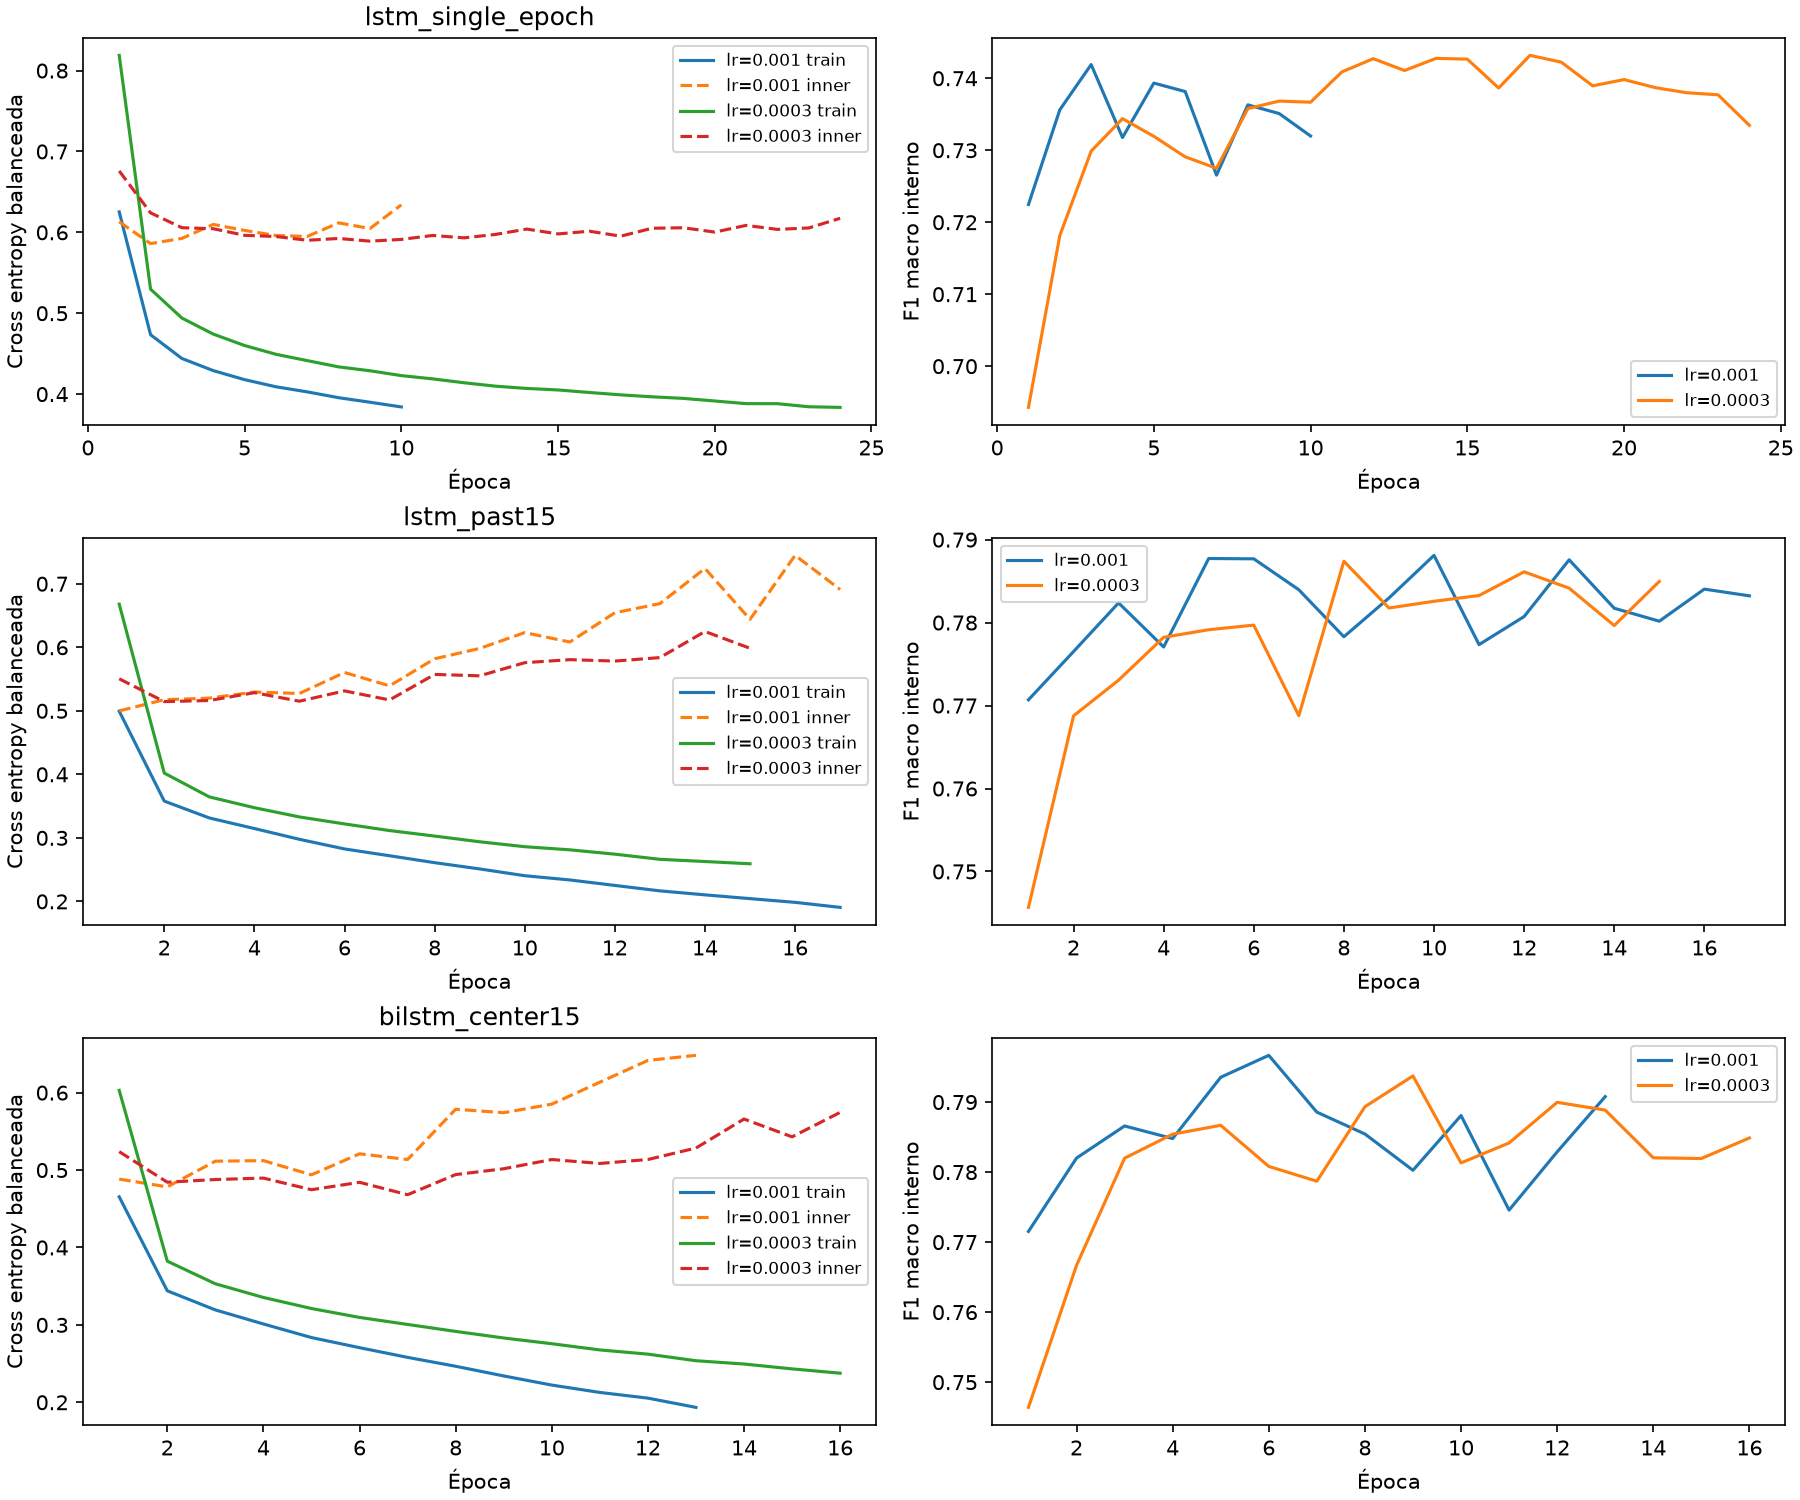

In [4]:
OUTPUT.joinpath("figures").mkdir(exist_ok=True)
fig, axes = plt.subplots(3, 2, figsize=(12, 10), constrained_layout=True)
for row, result in enumerate(campaign["neural_results"]):
    for trial in result["folds"][0]["trials"]:
        history = pd.read_json(Path(trial["directory"]) / "history.json")
        label = f"lr={trial['lr']}"
        axes[row, 0].plot(history.epoch, history.train_loss, label=label + " train")
        axes[row, 0].plot(history.epoch, history.inner_loss, linestyle="--", label=label + " inner")
        axes[row, 1].plot(history.epoch, history.inner_f1_macro, label=label)
    axes[row, 0].set(title=result["name"], xlabel="Época", ylabel="Cross entropy balanceada")
    axes[row, 1].set(xlabel="Época", ylabel="F1 macro interno")
    for ax in axes[row]:
        ax.legend(fontsize=8)
curves = OUTPUT / "figures/learning-curves.png"
fig.savefig(curves, dpi=150)
display(Image(filename=str(curves)))
plt.close(fig)


## Comparación con el campeón

La referencia LightGBM utiliza las mismas claves de segmentos y folds, con 435 variables y normalización de contexto por noche. Las redes usan 145 variables por segmento con escalado ajustado en entrenamiento. Se comparan soluciones completas; las diferencias no se atribuyen exclusivamente a la arquitectura.

F1 macro, accuracy y kappa se promedian entre cinco folds. La desviación entre folds no es un intervalo de confianza.

,name,f1_macro,f1_std,accuracy,kappa
0,lightgbm_context_offline,0.7822,0.0161,0.8167,0.7539
1,bilstm_center15,0.7687,0.0211,0.8007,0.7351
2,lstm_past15,0.7673,0.0184,0.8049,0.7388
3,lstm_single_epoch,0.7313,0.0250,0.7647,0.6887


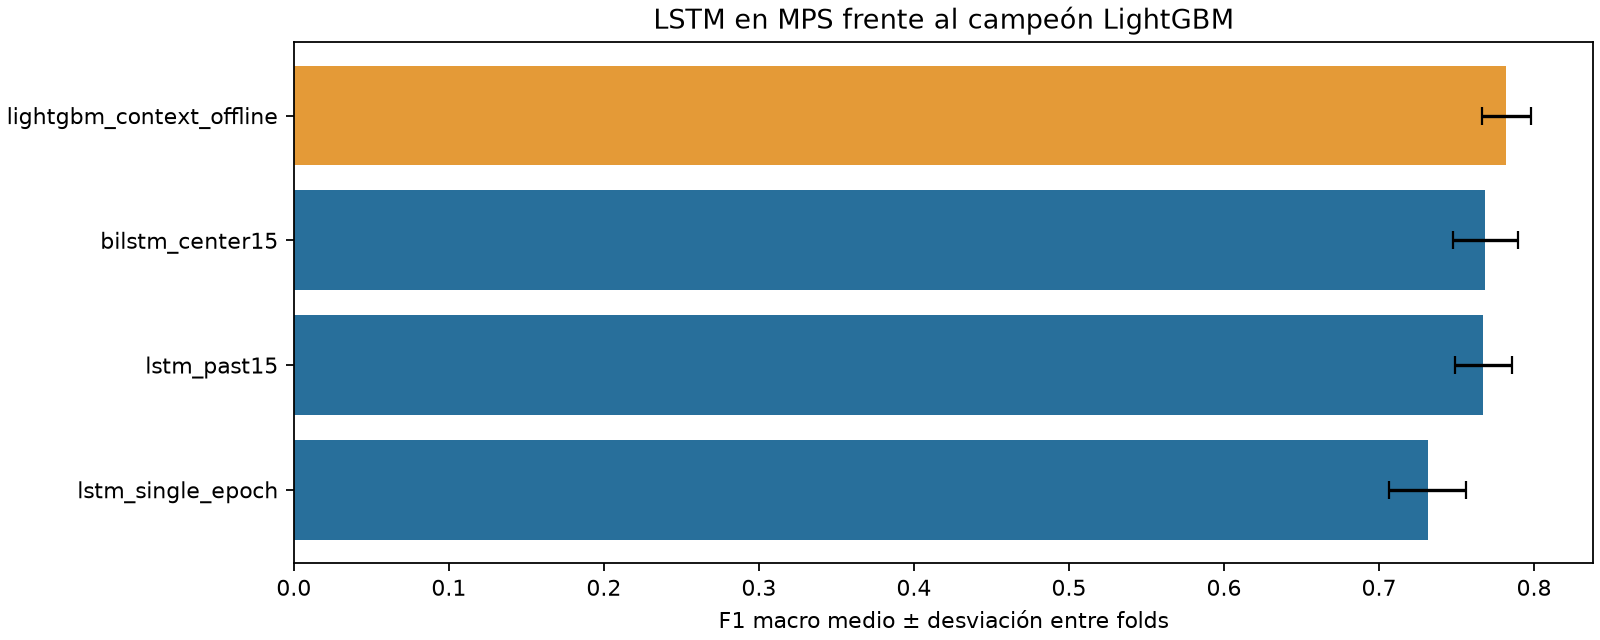

In [5]:
rows = [{k: r[k] for k in ["name", "f1_macro", "f1_std", "accuracy", "kappa"]} for r in campaign["neural_results"]]
rows.append({k: campaign["champion"][k] for k in ["name", "f1_macro", "f1_std", "accuracy", "kappa"]})
board = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(board.round(4))
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ordered = board.sort_values("f1_macro")
ax.barh(ordered.name, ordered.f1_macro, xerr=ordered.f1_std, capsize=4, color=["#E49A37" if n == campaign["champion"]["name"] else "#286F9B" for n in ordered.name])
ax.set(xlabel="F1 macro medio ± desviación entre folds", title="LSTM en MPS frente al campeón LightGBM")
comparison = OUTPUT / "figures/model-comparison.png"
fig.savefig(comparison, dpi=160)
display(Image(filename=str(comparison)))
plt.close(fig)


## Errores por estadio, sujeto e incertidumbre

El bootstrap emparejado utiliza 2.000 remuestreos de sujetos completos, con sus noches. Se calcula sobre predicciones OOF ya ajustadas; no cubre toda la variabilidad del reentrenamiento ni sustituye el test final. La comparación entre tres variantes conserva un carácter exploratorio.

,stage,precision,recall,f1-score,support,model
0,W,0.948361,0.889702,0.918096,48777.0,lightgbm_context_offline
1,N1,0.449704,0.626031,0.523416,16603.0,lightgbm_context_offline
2,N2,0.888118,0.777982,0.829410,54955.0,lightgbm_context_offline
3,N3,0.706116,0.900338,0.791486,10656.0,lightgbm_context_offline
4,REM,0.845003,0.860690,0.852774,21061.0,lightgbm_context_offline
5,W,0.963525,0.882752,0.921372,48777.0,bilstm_center15
6,N1,0.422611,0.672288,0.518982,16603.0,bilstm_center15
7,N2,0.898193,0.728050,0.804221,54955.0,bilstm_center15
8,N3,0.668393,0.896021,0.765647,10656.0,bilstm_center15
9,REM,0.816337,0.857462,0.836394,21061.0,bilstm_center15


f1_macro                      accuracy            \
                              mean    median       std      mean    median   
model                                                                        
bilstm_center15           0.720876  0.745830  0.098059  0.797987  0.807982   
lightgbm_context_offline  0.736399  0.750305  0.078936  0.814536  0.817796   

                                       kappa                      
                               std      mean    median       std  
model                                                             
bilstm_center15           0.072309  0.720217  0.732936  0.097749  
lightgbm_context_offline  0.056971  0.741689  0.752037  0.077500

,delta,ci95,subjects,repeats,scope
lstm_single_epoch,-0.051735,"[-0.06150123548857555, -0.043084438478451254]",62,2000,conditional_on_fitted_oof_models_not_final_test
lstm_past15,-0.014441,"[-0.023132667868236034, -0.005997323674350283]",62,2000,conditional_on_fitted_oof_models_not_final_test
bilstm_center15,-0.013713,"[-0.02260091551035303, -0.004924070864545343]",62,2000,conditional_on_fitted_oof_models_not_final_test


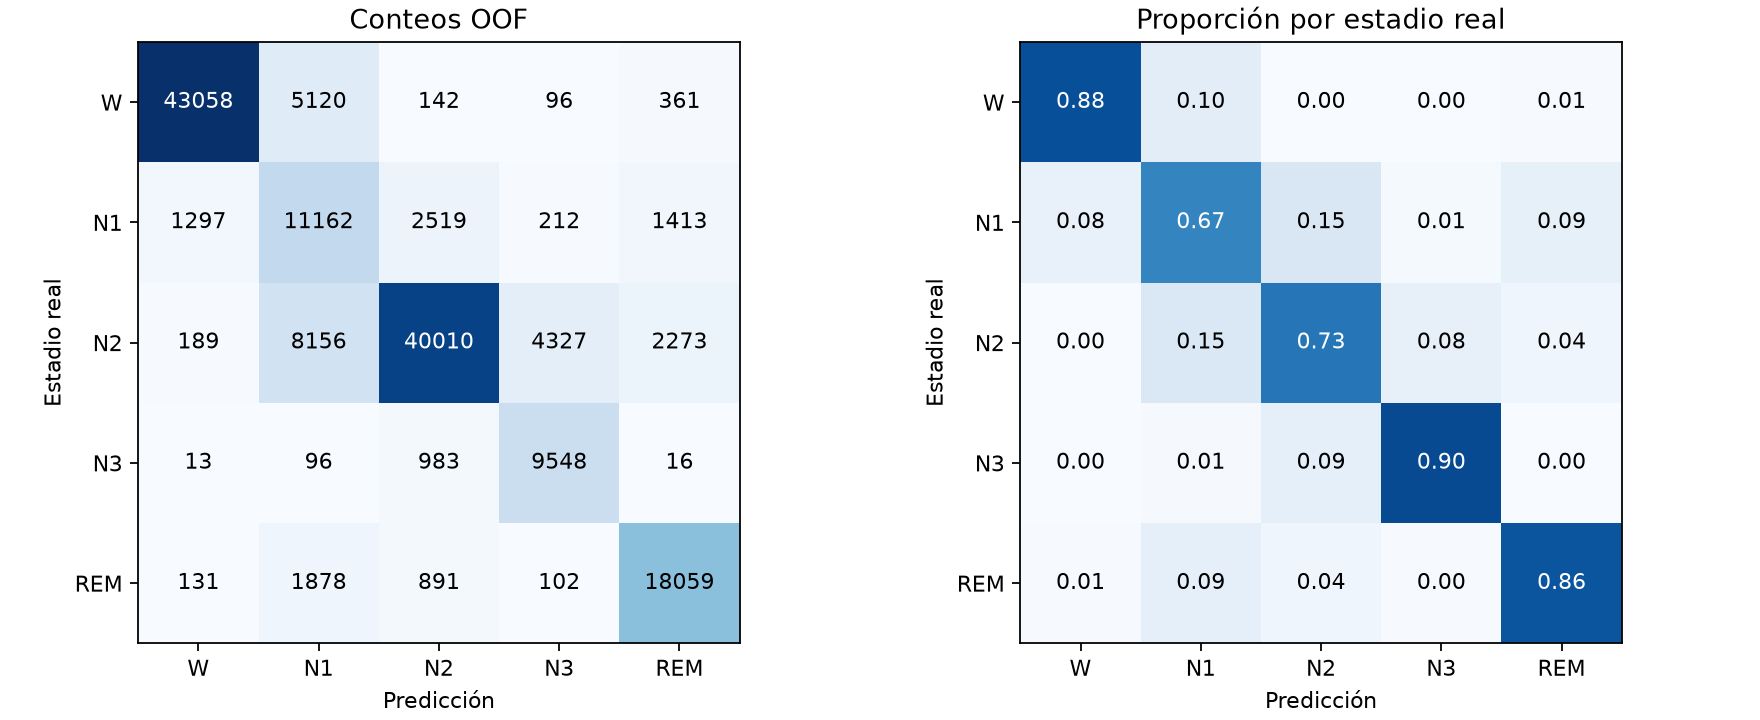

In [6]:
best = next(r for r in campaign["neural_results"] if r["name"] == campaign["best_neural"])
oof = pd.read_parquet(Path(best["directory"]) / "oof.parquet")
ref_oof = pd.read_parquet(Path(campaign["champion"]["run_dir"]) / "oof.parquet")
assert set(oof.epoch_id) == set(frame.epoch_id) and not oof.epoch_id.duplicated().any()
reports = []
subject_rows = []
for name, table in [(campaign["champion"]["name"], ref_oof), (best["name"], oof)]:
    metrics = evaluate(table.y_true.to_numpy(), table.y_pred.to_numpy(), CLASSES_5)
    report = pd.DataFrame(metrics["report"]).T.reindex(CLASSES_5)[["precision", "recall", "f1-score", "support"]]
    report["model"] = name
    reports.append(report.reset_index(names="stage"))
    for subject, group in table.groupby("subject_id", sort=True):
        m = evaluate(group.y_true.to_numpy(), group.y_pred.to_numpy(), CLASSES_5)
        subject_rows.append({"model": name, "subject_id": subject, **{k: m[k] for k in ["f1_macro", "accuracy", "kappa"]}})
display(pd.concat(reports, ignore_index=True))
subjects = pd.DataFrame(subject_rows)
subjects.to_csv(OUTPUT / "subject-metrics.csv", index=False)
display(subjects.groupby("model")[["f1_macro", "accuracy", "kappa"]].agg(["mean", "median", "std"]))
display(pd.DataFrame(campaign["paired_bootstrap"]).T[["delta", "ci95", "subjects", "repeats", "scope"]])
metrics = evaluate(oof.y_true.to_numpy(), oof.y_pred.to_numpy(), CLASSES_5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, key, title in zip(axes, ["confusion", "confusion_normalized"], ["Conteos OOF", "Proporción por estadio real"]):
    matrix = np.asarray(metrics[key])
    maximum = 1 if key.endswith("normalized") else matrix.max()
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=maximum)
    ax.set_xticks(range(5), CLASSES_5)
    ax.set_yticks(range(5), CLASSES_5)
    ax.set(xlabel="Predicción", ylabel="Estadio real", title=title)
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, f"{value:.2f}" if key.endswith("normalized") else str(int(value)), ha="center", va="center", color="white" if value > maximum * 0.5 else "black")
confusion = OUTPUT / "figures/neural-confusion.png"
fig.savefig(confusion, dpi=160)
display(Image(filename=str(confusion)))
plt.close(fig)


## Candidato, MLflow y conclusión

Se conserva un candidato neuronal con arquitectura, `state_dict`, escalador, columnas, clases y contrato de ventanas. Su entrada preparada tiene forma `[batch, longitud, 145]` y no es intercambiable con el CLI histórico de características tabulares. El alias previo de LightGBM permanece intacto.

La familia y las variantes se seleccionan en desarrollo. El test reservado se evaluará después de congelar el procedimiento final. El recorte supervisado y el uso de contexto futuro siguen siendo limitaciones para inferencia autónoma.

[MLflow local](http://127.0.0.1:5002): experimento `sleep-cassette-lstm-mps-v1`.

In [7]:
candidate = campaign["candidate"]
assert hash_file(Path(candidate["model_path"])) == candidate["model_sha256"]
assert candidate["reload_equal"] and candidate["probabilities_sum_to_one"]
print("Winner model:", campaign["overall_winner"])
print("Best neural model:", campaign["best_neural"])
print(f"Primary metric neural: F1 macro = {best['f1_macro']:.4f} +/- {best['f1_std']:.4f}")
print(f"Secondary metrics neural: accuracy={best['accuracy']:.4f}; kappa={best['kappa']:.4f}")
print("CV detail:", best["fold_scores"])
print(f"Delta mean CV F1 vs champion: {campaign['delta_cv_f1']:+.4f}")
print("Mejora sobre campeón:", campaign["delta_cv_f1"] > 0)
print("Key features: 145 multichannel signal features per segment")
print("Key params:", campaign["config"])
print("Device: MPS, float32, CPU fallback disabled")
print("MLflow parent:", campaign["mlflow_parent_run_id"])
print("Notebook: notebooks/05_lstm_mps.ipynb")
print("Next iteration: confirmar sensibilidad al recorte de vigilia antes de congelar el protocolo y evaluar el test final.")
print("Test evaluated:", campaign["test_evaluated"])


Winner model: lightgbm_context_offline
Best neural model: bilstm_center15
Primary metric neural: F1 macro = 0.7687 +/- 0.0211
Secondary metrics neural: accuracy=0.8007; kappa=0.7351
CV detail: [0.7308427905204681, 0.7652176675767992, 0.772566205958047, 0.7928017286686952, 0.7819162832875917]
Delta mean CV F1 vs champion: -0.0135
Mejora sobre campeón: False
Key features: 145 multichannel signal features per segment
Key params: {'device': 'mps', 'seed': 42, 'hidden_size': 64, 'dropout': 0.3, 'batch_size': 256, 'max_epochs': 50, 'patience': 7, 'min_delta': 0.0001, 'weight_decay': 0.0001, 'learning_rates': [0.001, 0.0003], 'variants': [{'name': 'lstm_single_epoch', 'length': 1, 'centered': False}, {'name': 'lstm_past15', 'length': 15, 'centered': False}, {'name': 'bilstm_center15', 'length': 15, 'centered': True}]}
Device: MPS, float32, CPU fallback disabled
MLflow parent: 0b66f79bb9c24dbfa20ab038d80bcbd9
Notebook: notebooks/05_lstm_mps.ipynb
Next iteration: confirmar sensibilidad al recor